# Part 3 — Ensemble Models and Hyperparameter Tuning
**Project:** Social Media Impact on Student Life  
**Continuation:** Part 1 and Part 2  
**Target:** `Overall_Impact` (Negative / Neutral / Beneficial)

This notebook uses the **same profile + social-media-use features** and the same **80/20 stratified split** as Part 2 (random state 42). Sleep, stress, mental health and GPA are excluded because Part 2 treated them as possible outcome leakage. All preprocessing runs inside each model pipeline.

**Models:** Random Forest, AdaBoost, XGBoost, Elastic Net Logistic Regression. **Tuning:** RandomizedSearchCV, 5 folds, 5 choices per model, macro-F1 scoring.

## 1. Import libraries

In [1]:
# Run in Google Colab if XGBoost is not installed:
# !pip install xgboost
import os
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
print("Libraries loaded")

Libraries loaded


## 2. Upload the same CSV from Parts 1 and 2

In [3]:
csv_files = sorted(Path('.').glob('Social_media_impact_on_life*.csv'))
if not csv_files:
    from google.colab import files
    files.upload()
    csv_files = sorted(Path('.').glob('Social_media_impact_on_life*.csv'))
assert csv_files, "Please upload Social_media_impact_on_life.csv"
df = pd.read_csv(csv_files[0])
print("File:", csv_files[0])
print("Rows and columns:", df.shape)
print(df['Overall_Impact'].value_counts())

Saving Social_media_impact_on_life (2).csv to Social_media_impact_on_life (2).csv
File: Social_media_impact_on_life (2).csv
Rows and columns: (4500, 16)
Overall_Impact
Beneficial    3681
Neutral        654
Negative       165
Name: count, dtype: int64


## 3. Same cleaning, features and split as Part 2

In [4]:
# Apply the same range checks used in the Part 2 notebook.
bad = (
    ~df['Age'].between(13, 30) |
    (df['Academic_Performance_GPA'].notna() & ~df['Academic_Performance_GPA'].between(0, 4)) |
    (df['Perceived_Stress_Score'].notna() & ~df['Perceived_Stress_Score'].between(0, 40)) |
    ~df['Mental_Health_Index'].between(0, 100) |
    ~df['Sleep_Quality_Score'].between(1, 5) |
    ~df['Daily_Usage_Hours'].between(0, 24) |
    ((df['Daily_Usage_Hours'] + df['Weekend_Extra_Hours']) > 24) |
    ((df['Sleep_Duration_Hours'] + df['Daily_Usage_Hours']) > 24)
)
df = df.loc[~bad].drop_duplicates().copy()
df['Late_Night_Usage'] = df['Late_Night_Usage'].astype(int)

features = ['Age', 'Gender', 'Academic_Level', 'Primary_Platform',
            'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
            'Late_Night_Usage', 'Social_Comparison_Frequency']
X = df[features].copy()
class_names = ['Negative', 'Neutral', 'Beneficial']
y = df['Overall_Impact'].map({name: i for i, name in enumerate(class_names)}).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print('Training:', len(X_train), '| Testing:', len(X_test))

Training: 3600 | Testing: 900


## 4. Same preprocessing as Part 2

In [5]:
# These two new columns also appeared in the Part 2 notebook.
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X['Weekend_Day_Usage_Hours'] = X['Daily_Usage_Hours'] + X['Weekend_Extra_Hours']
        X['Weekend_Extra_Share'] = X['Weekend_Extra_Hours'] / X['Daily_Usage_Hours'].replace(0, np.nan)
        return X

num_cols = ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours',
            'Weekend_Day_Usage_Hours', 'Weekend_Extra_Share']
preprocess = Pipeline([
    ('features', FeatureBuilder()),
    ('preprocessor', ColumnTransformer([
        ('numeric', Pipeline([
            ('fill', SimpleImputer(strategy='median')),
            ('scale', RobustScaler())]), num_cols),
        ('binary', SimpleImputer(strategy='most_frequent'), ['Late_Night_Usage']),
        ('ordinal', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('encode', OrdinalEncoder(categories=[
                ['High School', 'Undergraduate', 'Postgraduate'],
                ['Never', 'Rarely', 'Sometimes', 'Frequently', 'Always']],
                handle_unknown='use_encoded_value', unknown_value=-1))]),
            ['Academic_Level', 'Social_Comparison_Frequency']),
        ('nominal', Pipeline([
            ('fill', SimpleImputer(strategy='constant', fill_value='Unknown')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
            ['Gender', 'Primary_Platform', 'Device_Type'])
    ]))
])
print('Preprocessing ready')

Preprocessing ready


## 5. Tune the four models

We test **5 random hyperparameter combinations per model**, with **5-fold cross-validation** on the training rows. We choose settings with the highest validation macro-F1. The held-out test rows are not used when choosing the settings.

In [6]:
models = {
    'Random Forest': (
        RandomForestClassifier(random_state=42, n_jobs=1, class_weight='balanced'),
        {'model__n_estimators': [100, 200],
         'model__max_depth': [5, 10, None],
         'model__min_samples_leaf': [1, 3]}),
    'AdaBoost': (
        AdaBoostClassifier(random_state=42),
        {'model__n_estimators': [50, 100, 150],
         'model__learning_rate': [0.05, 0.1, 0.5, 1.0]}),
    'XGBoost': (
        XGBClassifier(random_state=42, n_jobs=1, eval_metric='mlogloss', tree_method='hist'),
        {'model__n_estimators': [100, 200],
         'model__max_depth': [2, 3, 5],
         'model__learning_rate': [0.05, 0.1]}),
    'Elastic Net': (
        LogisticRegression(penalty='elasticnet', solver='saga', max_iter=3000, random_state=42),
        {'model__C': [0.1, 1, 10],
         'model__l1_ratio': [0.2, 0.5, 0.8]})
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
searches = {}
for name, (classifier, settings) in models.items():
    pipeline = Pipeline([('preprocessing', clone(preprocess)), ('model', classifier)])
    search = RandomizedSearchCV(pipeline, settings, n_iter=5, scoring='f1_macro',
                                cv=cv, random_state=42, n_jobs=2)
    search.fit(X_train, y_train)
    searches[name] = search
    print(name, '| CV macro-F1:', round(search.best_score_, 3))
    print('Best settings:', search.best_params_)

Random Forest | CV macro-F1: 0.763
Best settings: {'model__n_estimators': 100, 'model__min_samples_leaf': 3, 'model__max_depth': None}
AdaBoost | CV macro-F1: 0.769
Best settings: {'model__n_estimators': 150, 'model__learning_rate': 0.5}
XGBoost | CV macro-F1: 0.752
Best settings: {'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Elastic Net | CV macro-F1: 0.761
Best settings: {'model__l1_ratio': 0.5, 'model__C': 10}


## 6. Held-out results and original Part 2 baselines

In [7]:
# Score each tuned model once on the untouched test set.
results = []
for name, search in searches.items():
    prediction = search.predict(X_test)
    probabilities = search.predict_proba(X_test)
    results.append({
        'Model': name,
        'CV Macro-F1': search.best_score_,
        'Test Accuracy': accuracy_score(y_test, prediction),
        'Test Macro-F1': f1_score(y_test, prediction, average='macro'),
        'Test Balanced Accuracy': balanced_accuracy_score(y_test, prediction),
        'Test ROC-AUC': roc_auc_score(y_test, probabilities, multi_class='ovr', average='macro')
    })

# Fit original Part 2 baselines on the SAME training split for a fair test comparison.
for name, classifier in [('Gaussian Naive Bayes', GaussianNB()),
                         ('Decision Tree', DecisionTreeClassifier(criterion='gini', random_state=42))]:
    model = Pipeline([('preprocessing', clone(preprocess)), ('model', classifier)])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    probabilities = model.predict_proba(X_test)
    results.append({
        'Model': name, 'CV Macro-F1': np.nan,
        'Test Accuracy': accuracy_score(y_test, prediction),
        'Test Macro-F1': f1_score(y_test, prediction, average='macro'),
        'Test Balanced Accuracy': balanced_accuracy_score(y_test, prediction),
        'Test ROC-AUC': roc_auc_score(y_test, probabilities, multi_class='ovr', average='macro')
    })

results_table = pd.DataFrame(results)
print(results_table.round(3).to_string(index=False))
results_table.to_csv('Part3_model_comparison.csv', index=False)

               Model  CV Macro-F1  Test Accuracy  Test Macro-F1  Test Balanced Accuracy  Test ROC-AUC
       Random Forest        0.763          0.859          0.708                   0.730         0.937
            AdaBoost        0.769          0.854          0.688                   0.719         0.883
             XGBoost        0.752          0.872          0.703                   0.688         0.943
         Elastic Net        0.761          0.880          0.692                   0.664         0.947
Gaussian Naive Bayes          NaN          0.843          0.705                   0.783         0.925
       Decision Tree          NaN          0.851          0.665                   0.663         0.761


## 7. Final chosen model and class results

Chosen by CV: AdaBoost
              precision    recall  f1-score   support

    Negative       0.55      0.70      0.61        33
     Neutral       0.50      0.54      0.52       131
  Beneficial       0.94      0.92      0.93       736

    accuracy                           0.85       900
   macro avg       0.66      0.72      0.69       900
weighted avg       0.86      0.85      0.86       900



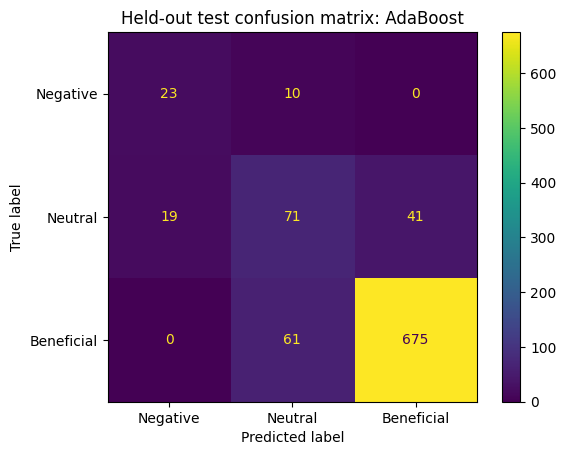

In [8]:
# Selection uses CV macro-F1, not the final test results.
best_name = max(searches, key=lambda n: searches[n].best_score_)
best = searches[best_name]
print('Chosen by CV:', best_name)
prediction = best.predict(X_test)
print(classification_report(y_test, prediction, labels=[0, 1, 2],
                            target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, prediction,
                                        display_labels=class_names)
plt.title('Held-out test confusion matrix: ' + best_name)
plt.show()

## 8. Conclusion and remaining plan

The model chosen by **training cross-validation** is **AdaBoost**, but this does not mean it must win every held-out metric. **Gaussian Naive Bayes remains a strong original baseline**; report both its strengths and weaknesses. A higher accuracy score alone does not prove a better model on this imbalanced dataset.

**Next:** Complete Part 4 analysis, assess recall for the Negative class, consider fairness across student groups, prepare the final report, GitHub repository and presentation.

**Limitations:** One dataset, imbalanced classes, possible outcome leakage, and possible optimism if models are selected using test data. The notebook avoids the last issue by selecting using CV first.